In [1]:
import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import (
    Input,
    Embedding,
    Dense,
    Dropout,
    LayerNormalization,
    MultiHeadAttention,
    GlobalAveragePooling1D
)
from tensorflow.keras.models import Model
from sklearn.model_selection import train_test_split

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)
print("Project environment initialized successfully.")

TensorFlow version: 2.21.0
GPU available: False
Project environment initialized successfully.


In [2]:
sentences = [
    "the cat sits on the mat",
    "the cat eats fresh fish",
    "the dog plays in the garden",
    "the dog runs in the park",
    "a cat likes warm milk",
    "a dog likes playing outside",
    "the bird flies in the sky",
    "the bird sings in the morning",
    "the sun shines in the blue sky",
    "the moon appears at night",
    "machine learning helps computers learn patterns",
    "deep learning uses neural networks",
    "a neural network learns from data",
    "artificial intelligence can solve problems",
    "transformers use attention to understand context",
    "self attention learns relationships between tokens",
    "a computer processes text using numbers",
    "natural language processing works with human language",
    "the student studies machine learning",
    "the student writes Python code",
    "Python is useful for artificial intelligence",
    "data helps a model learn patterns",
    "the model predicts the next word",
    "the model learns from training examples",
    "attention helps identify important words",
    "the teacher explains the lesson",
    "the student reads a book",
    "the book contains useful information",
    "we build a neural network model",
    "we train the model using text data",
    "the weather is sunny today",
    "the weather is rainy today",
    "the flowers grow in the garden",
    "the farmer grows fresh vegetables",
    "the child reads an interesting story",
    "the story describes a beautiful forest",
    "the river flows through the valley",
    "birds build nests in trees",
    "the computer generates a sentence",
    "language models predict upcoming tokens",
    "a transformer processes a sequence of tokens",
    "causal attention prevents looking at future tokens",
    "the network calculates probabilities for each token",
    "the next word depends on previous context",
    "the student builds a transformer model",
    "we evaluate the trained neural network",
    "the model generates new text from a prompt",
    "learning algorithms discover patterns in data",
    "the dog sleeps near the house",
    "the cat sleeps near the window"
]

print("Number of sentences:", len(sentences))
print("\nExample sentence:", sentences[0])

Number of sentences: 50

Example sentence: the cat sits on the mat


In [3]:
tokenizer = Tokenizer(
    filters="",
    lower=True,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(sentences)

word_index = tokenizer.word_index
vocab_size = len(word_index) + 1

CONTEXT_LENGTH = 8

X, y = [], []

for sentence in sentences:
    token_ids = tokenizer.texts_to_sequences([sentence])[0]

    # Each prefix is used to predict its next token.
    for i in range(1, len(token_ids)):
        context = token_ids[max(0, i - CONTEXT_LENGTH):i]

        padded_context = pad_sequences(
            [context],
            maxlen=CONTEXT_LENGTH,
            padding="pre",
            truncating="pre",
            value=0
        )[0]

        X.append(padded_context)
        y.append(token_ids[i])

X = np.array(X, dtype=np.int32)
y = np.array(y, dtype=np.int32)

print("Vocabulary size:", vocab_size)
print("Context length:", CONTEXT_LENGTH)
print("Training examples before splitting:", len(X))
print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("\nExample input token IDs:", X[0])
print("Example target token ID:", y[0])

Vocabulary size: 153
Context length: 8
Training examples before splitting: 241
Input shape: (241, 8)
Target shape: (241,)

Example input token IDs: [0 0 0 0 0 0 0 2]
Example target token ID: 6


In [4]:
tokenizer = Tokenizer(
    filters="",
    lower=True,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(sentences)

word_index = tokenizer.word_index
vocab_size = len(word_index) + 1

CONTEXT_LENGTH = 8

X, y = [], []

for sentence in sentences:
    token_ids = tokenizer.texts_to_sequences([sentence])[0]

    # Each prefix is used to predict its next token.
    for i in range(1, len(token_ids)):
        context = token_ids[max(0, i - CONTEXT_LENGTH):i]

        padded_context = pad_sequences(
            [context],
            maxlen=CONTEXT_LENGTH,
            padding="pre",
            truncating="pre",
            value=0
        )[0]

        X.append(padded_context)
        y.append(token_ids[i])

X = np.array(X, dtype=np.int32)
y = np.array(y, dtype=np.int32)

print("Vocabulary size:", vocab_size)
print("Context length:", CONTEXT_LENGTH)
print("Training examples before splitting:", len(X))
print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("\nExample input token IDs:", X[0])
print("Example target token ID:", y[0])

Vocabulary size: 153
Context length: 8
Training examples before splitting: 241
Input shape: (241, 8)
Target shape: (241,)

Example input token IDs: [0 0 0 0 0 0 0 2]
Example target token ID: 6


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED
)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))

Training examples: 192
Testing examples: 49


In [6]:
EMBEDDING_DIM = 64
NUM_HEADS = 4
FF_DIM = 128
DROPOUT_RATE = 0.1


def build_transformer(
    vocab_size,
    context_length,
    embedding_dim=64,
    num_heads=4,
    ff_dim=128
):
    token_inputs = Input(
        shape=(context_length,),
        dtype="int32",
        name="token_ids"
    )

    # Token embeddings
    token_embeddings = Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        mask_zero=False,
        name="token_embedding"
    )(token_inputs)

    # Learnable positional embeddings
    positions = tf.range(start=0, limit=context_length, delta=1)

    position_embeddings = Embedding(
        input_dim=context_length,
        output_dim=embedding_dim,
        name="position_embedding"
    )(positions)

    x = token_embeddings + position_embeddings

    # Basic causal self-attention
    attention_output = MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embedding_dim // num_heads,
        dropout=DROPOUT_RATE,
        name="causal_self_attention"
    )(
        query=x,
        value=x,
        key=x,
        use_causal_mask=True
    )

    x = LayerNormalization(
        epsilon=1e-6,
        name="attention_layer_norm"
    )(x + attention_output)

    # Feed-forward network
    ff_output = Dense(
        ff_dim,
        activation="relu",
        name="feed_forward_1"
    )(x)

    ff_output = Dense(
        embedding_dim,
        name="feed_forward_2"
    )(ff_output)

    ff_output = Dropout(DROPOUT_RATE)(ff_output)

    x = LayerNormalization(
        epsilon=1e-6,
        name="feed_forward_layer_norm"
    )(x + ff_output)

    # Use the representation at the final context position
    x = tf.keras.layers.Lambda(
        lambda tensor: tensor[:, -1, :],
        name="last_position"
    )(x)

    outputs = Dense(
        vocab_size,
        activation="softmax",
        name="next_token_probabilities"
    )(x)

    model = Model(
        inputs=token_inputs,
        outputs=outputs,
        name="Basic_Self_Attention_Transformer"
    )

    return model


model = build_transformer(
    vocab_size=vocab_size,
    context_length=CONTEXT_LENGTH,
    embedding_dim=EMBEDDING_DIM,
    num_heads=NUM_HEADS,
    ff_dim=FF_DIM
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "Basic_Self_Attention_Transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ token_ids           │ (None, 8)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_embedding     │ (None, 8, 64)     │      9,792 │ token_ids[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 8, 64)     │          0 │ token_embedding[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ causal_self_attent… │ (None, 8, 64)     │     16,640 │ add[0][0],        │
│ (MultiHeadAttentio… │                   │            │ add[0][0],        │
│                     │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 8, 64)     │          0 │ add[0][0],        │
│                     │                   │            │ causal_self_atte… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_layer_no… │ (None, 8, 64)     │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feed_forward_1      │ (None, 8, 128)    │      8,320 │ attention_layer_… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feed_forward_2      │ (None, 8, 64)     │      8,256 │ feed_forward_1[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 8, 64)     │          0 │ feed_forward_2[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 8, 64)     │          0 │ attention_layer_… │
│                     │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feed_forward_layer… │ (None, 8, 64)     │        128 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ last_position       │ (None, 64)        │          0 │ feed_forward_lay… │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ next_token_probabi… │ (None, 153)       │      9,945 │ last_position[0]… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 53,209 (207.85 KB)

 Trainable params: 53,209 (207.85 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
EPOCHS = 100
BATCH_SIZE = 16

history = model.fit(
    X_train,
    y_train,
    validation_split=0.15,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    verbose=1
)

print("\nTraining completed successfully.")

Epoch 1/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.0245 - loss: 5.2043 - val_accuracy: 0.1034 - val_loss: 5.1042
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.1595 - loss: 4.3632 - val_accuracy: 0.1034 - val_loss: 5.2701
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.3067 - loss: 3.7643 - val_accuracy: 0.0345 - val_loss: 5.3314
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.4479 - loss: 3.1664 - val_accuracy: 0.0345 - val_loss: 5.3050
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.6319 - loss: 2.6468 - val_accuracy: 0.0345 - val_loss: 5.3783
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.6503 - loss: 2.2229 - val_accuracy: 0.0345 - val_loss: 5.4559
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.6135 - loss: 1.9228 - val_accuracy: 0.0345 - val_loss: 5.5791
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6503 - loss: 1.7005 - val_accuracy: 0.

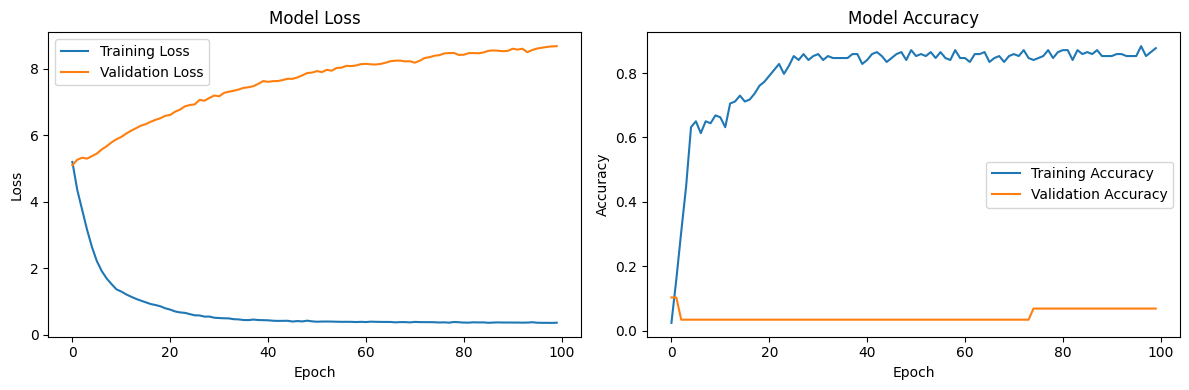

In [8]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.savefig("training_history.png", dpi=150)
plt.show()

In [9]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Results")
print("-" * 30)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy (%): {test_accuracy * 100:.2f}%")

Test Results
------------------------------
Test Loss: 7.6125
Test Accuracy: 0.1020
Test Accuracy (%): 10.20%


In [10]:
index_word = {
    index: word
    for word, index in word_index.items()
}


def predict_next_token(prompt):
    token_ids = tokenizer.texts_to_sequences([prompt])[0]

    if not token_ids:
        raise ValueError(
            "The prompt contains no recognized tokens. Try another prompt."
        )

    context = token_ids[-CONTEXT_LENGTH:]

    padded_context = pad_sequences(
        [context],
        maxlen=CONTEXT_LENGTH,
        padding="pre",
        truncating="pre",
        value=0
    )

    probabilities = model.predict(padded_context, verbose=0)[0]

    # Return the five highest-probability token predictions
    top_indices = np.argsort(probabilities)[::-1][:5]

    results = []
    for idx in top_indices:
        if idx == 0:
            continue

        results.append({
            "Token": index_word.get(int(idx), "<UNKNOWN>"),
            "Probability": float(probabilities[idx])
        })

    return pd.DataFrame(results)


prompt = "the cat"

predictions = predict_next_token(prompt)

print("Input prompt:", prompt)
print("\nTop next-token predictions:")
display(predictions)

Input prompt: the cat

Top next-token predictions:


,Token,Probability
0,sleeps,0.996256
1,the,0.000242
2,a,0.000242
3,from,0.000173
4,dog,0.000164


In [11]:
def generate_text(prompt, max_new_tokens=10):
    generated_text = prompt.strip()

    for _ in range(max_new_tokens):
        token_ids = tokenizer.texts_to_sequences(
            [generated_text]
        )[0]

        if not token_ids:
            break

        context = token_ids[-CONTEXT_LENGTH:]

        padded_context = pad_sequences(
            [context],
            maxlen=CONTEXT_LENGTH,
            padding="pre",
            truncating="pre",
            value=0
        )

        probabilities = model.predict(
            padded_context,
            verbose=0
        )[0]

        # Exclude padding ID 0
        probabilities[0] = 0

        next_id = int(np.argmax(probabilities))

        if next_id not in index_word:
            break

        next_word = index_word[next_id]
        generated_text += " " + next_word

    return generated_text


print(generate_text("the cat", max_new_tokens=10))
print(generate_text("machine learning", max_new_tokens=10))
print(generate_text("the student", max_new_tokens=10))

the cat sleeps near the house an interesting story describes a beautiful
machine learning helps computers learn patterns in the garden beautiful forest in
the student writes in the student writes in the sky transformer model


In [12]:
PROJECT_DIR = "transformer_next_token_project"
os.makedirs(PROJECT_DIR, exist_ok=True)

# Save trained Keras model
model.save(
    os.path.join(PROJECT_DIR, "transformer_model.keras")
)

# Save tokenizer vocabulary and configuration
with open(
    os.path.join(PROJECT_DIR, "tokenizer.json"),
    "w",
    encoding="utf-8"
) as f:
    f.write(tokenizer.to_json())

# Save training configuration
config = {
    "project_name": "Transformer-Based Next-Token Prediction",
    "context_length": CONTEXT_LENGTH,
    "vocab_size": vocab_size,
    "embedding_dim": EMBEDDING_DIM,
    "num_heads": NUM_HEADS,
    "feed_forward_dim": FF_DIM,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
    "seed": SEED
}

with open(
    os.path.join(PROJECT_DIR, "config.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(config, f, indent=4)

# Save evaluation results
results = pd.DataFrame([{
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
    "test_accuracy_percent": float(test_accuracy * 100)
}])

results.to_csv(
    os.path.join(PROJECT_DIR, "evaluation_results.csv"),
    index=False
)

# Copy the training graph into the project folder
import shutil

shutil.copy(
    "training_history.png",
    os.path.join(PROJECT_DIR, "training_history.png")
)

print("Project artifacts saved successfully!")
print("Project directory:", PROJECT_DIR)
print("Files:", os.listdir(PROJECT_DIR))

Project artifacts saved successfully!
Project directory: transformer_next_token_project
Files: ['config.json', 'training_history.png', 'evaluation_results.csv', 'tokenizer.json', 'transformer_model.keras']


In [13]:
saved_model_path = os.path.join(
    PROJECT_DIR,
    "transformer_model.keras"
)

# This model contains a Lambda layer from Cell 5.
loaded_model = tf.keras.models.load_model(
    saved_model_path,
    safe_mode=False
)

# Reconstruct the tokenizer from the saved JSON
with open(
    os.path.join(PROJECT_DIR, "tokenizer.json"),
    "r",
    encoding="utf-8"
) as f:
    loaded_tokenizer = tf.keras.preprocessing.text.tokenizer_from_json(
        f.read()
    )

test_prompt = "the cat"

token_ids = loaded_tokenizer.texts_to_sequences(
    [test_prompt]
)[0]

padded = pad_sequences(
    [token_ids[-CONTEXT_LENGTH:]],
    maxlen=CONTEXT_LENGTH,
    padding="pre",
    truncating="pre"
)

probabilities = loaded_model.predict(padded, verbose=0)[0]
predicted_id = int(np.argmax(probabilities))

loaded_index_word = {
    idx: word
    for word, idx in loaded_tokenizer.word_index.items()
}

print("Saved model loaded successfully!")
print("Tokenizer loaded successfully!")
print("Test prompt:", test_prompt)
print("Predicted next token:", loaded_index_word.get(
    predicted_id, "<UNKNOWN>"
))
print("Prediction confidence:", round(float(probabilities[predicted_id]), 4))

Saved model loaded successfully!
Tokenizer loaded successfully!
Test prompt: the cat
Predicted next token: sleeps
Prediction confidence: 0.9963


In [14]:
readme = """# Transformer-Based Next-Token Prediction

## Project Overview
This project implements a small Transformer language model that predicts
the next token in a text sequence using causal self-attention.

## Technologies
- Python
- TensorFlow / Keras
- NumPy
- Pandas
- Matplotlib
- scikit-learn
- Google Colab

## Model Architecture
1. Token embedding
2. Learnable positional embedding
3. Multi-head causal self-attention
4. Layer normalization and residual connections
5. Feed-forward neural network
6. Softmax next-token prediction layer

## Dataset
A small custom collection of English sentences is used for demonstration.
The model is intended for learning and experimentation, not production use.

## How to Run
1. Open Transformer_Next_Token_Prediction.ipynb in Google Colab.
2. Run the notebook cells in order.
3. Train and evaluate the model.
4. Try custom prompts and generate text.
5. Save and reload the trained model.

## Output Files
- transformer_model.keras: trained model
- tokenizer.json: tokenizer configuration
- config.json: model and training settings
- evaluation_results.csv: test evaluation results
- training_history.png: loss and accuracy plots

## Limitations
The dataset is small, so generated text may be repetitive or grammatically
incorrect. Test accuracy on this dataset does not demonstrate general
language understanding.

## Future Improvements
- Train on a larger, more diverse dataset.
- Compare greedy decoding with top-k or temperature sampling.
- Evaluate on held-out sentences from a separate dataset.
- Experiment with multiple Transformer blocks.
"""

with open(
    os.path.join(PROJECT_DIR, "README.md"),
    "w",
    encoding="utf-8"
) as f:
    f.write(readme)

requirements = """tensorflow
numpy
pandas
matplotlib
scikit-learn
"""

with open(
    os.path.join(PROJECT_DIR, "requirements.txt"),
    "w",
    encoding="utf-8"
) as f:
    f.write(requirements)

print("README.md and requirements.txt created.")
print(os.listdir(PROJECT_DIR))

README.md and requirements.txt created.
['config.json', 'requirements.txt', 'training_history.png', 'evaluation_results.csv', 'tokenizer.json', 'README.md', 'transformer_model.keras']


In [15]:
import shutil

zip_path = shutil.make_archive(
    "transformer_next_token_project",
    "zip",
    root_dir=".",
    base_dir=PROJECT_DIR
)

print("ZIP archive created:", zip_path)

ZIP archive created: /content/transformer_next_token_project.zip


In [16]:
from google.colab import files

files.download("transformer_next_token_project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>